<a href="https://colab.research.google.com/github/HoangMinhne0903/6451071046_Lab1_Phan_2/blob/main/6451071046_LAB1_Bai5a_Trang45.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài 5a (Trang 45): Luật kết hợp - Germany & France


## Câu 5a: Nước Đức (Germany) - min_sup=5%, min_conf=50%

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# !pip install mlxtend xlrd openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Đọc dữ liệu Online Retail
df = pd.read_excel("Online Retail.xlsx", dtype={"InvoiceNo": str})

# Tiền xử lý
df["Description"] = df["Description"].str.strip()
df.dropna(subset=["InvoiceNo"], inplace=True)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.contains("C")]

# Lấy dữ liệu Germany
basket_de = (df[df["Country"] == "Germany"]
             .groupby(["InvoiceNo", "Description"])["Quantity"]
             .sum().unstack().reset_index().fillna(0)
             .set_index("InvoiceNo"))

# Hot encoding -> bool
basket_de_bool = basket_de.applymap(lambda x: 1 if x >= 1 else 0).astype(bool)

# Xóa cột POSTAGE nếu có
if "POSTAGE" in basket_de_bool.columns:
    basket_de_bool.drop(columns=["POSTAGE"], inplace=True)

print(f"Dữ liệu Germany: {basket_de_bool.shape[0]} hóa đơn, {basket_de_bool.shape[1]} mặt hàng")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046


Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().

Dữ liệu Germany: 457 hóa đơn, 1694 mặt hàng


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# APRIORI - Germany (min_sup=5%, min_conf=50%)
print("=" * 60)
print("5a. APRIORI - Germany | min_sup=5%, min_conf=50%")
print("=" * 60)

freq_de = apriori(basket_de_bool, min_support=0.05, use_colnames=True)
freq_de = freq_de.sort_values("support", ascending=False)
print(f"Số tập phổ biến: {len(freq_de)}")
print("Top 15 tập phổ biến:")
print(freq_de.head(15))

rules_de = association_rules(freq_de, metric="confidence", min_threshold=0.5)
rules_de = rules_de.sort_values(["confidence", "lift"], ascending=[False, False])
print(f"\nSố luật kết hợp: {len(rules_de)}")
print("\nTop 15 luật kết hợp:")
print(rules_de[["antecedents", "consequents", "support", "confidence", "lift"]].head(15))


Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
5a. APRIORI - Germany | min_sup=5%, min_conf=50%
Số tập phổ biến: 59
Top 15 tập phổ biến:
     support                                           itemsets
35  0.245077               (ROUND SNACK BOXES SET OF4 WOODLAND)
34  0.157549                (ROUND SNACK BOXES SET OF 4 FRUITS)
24  0.137856                 (PLASTERS IN TIN WOODLAND ANIMALS)
31  0.137856                         (REGENCY CAKESTAND 3 TIER)
56  0.131291  (ROUND SNACK BOXES SET OF4 WOODLAND, ROUND SNA...
48  0.126915                           (WOODLAND CHARLOTTE BAG)
21  0.115974                    (PLASTERS IN TIN CIRCUS PARADE)
22  0.107221                         (PLASTERS IN TIN SPACEBOY)
0   0.102845                           (6 RIBBONS RUSTIC CHARM)
44  0.102845                               (SPACEBOY LUNCH BOX)
12  0.100656                       (JUMBO BAG WOODLAND ANIMALS)
30  0.096280                    (RED TOADSTOOL LED NIGHT LIGHT)
9   0.091904               

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
5a. FP-GROWTH - Germany | min_sup=5%, min_conf=50%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Số tập phổ biến (FP-Growth): 59
Số luật kết hợp (FP-Growth): 8

Top 15 luật:
                            antecedents                           consequents  \
5         (RED RETROSPOT CHARLOTTE BAG)              (WOODLAND CHARLOTTE BAG)   
1   (ROUND SNACK BOXES SET OF 4 FRUITS)  (ROUND SNACK BOXES SET OF4 WOODLAND)   
4                  (SPACEBOY LUNCH BOX)  (ROUND SNACK BOXES SET OF4 WOODLAND)   
3       (PLASTERS IN TIN CIRCUS PARADE)    (PLASTERS IN TIN WOODLAND ANIMALS)   
7            (PLASTERS IN TIN SPACEBOY)    (PLASTERS IN TIN WOODLAND ANIMALS)   
6    (PLASTERS IN TIN WOODLAND ANIMALS)  (ROUND SNACK BOXES SET OF4 WOODLAND)   
0  (ROUND SNACK BOXES SET OF4 WOODLAND)   (ROUND SNACK BOXES SET OF 4 FRUITS)   
2              (WOODLAND CHARLOTTE BAG)  (ROUND SNACK BOXES SET OF4 WOODLAND)   

    support  confidence      lift  
5  0.059081    0.843750  6.648168  
1  0.131291    0.833333  3.400298  
4  0.070022    0.680851  2.778116  
3  0.067834    0.584906  4.242887  
7  0.061269  

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

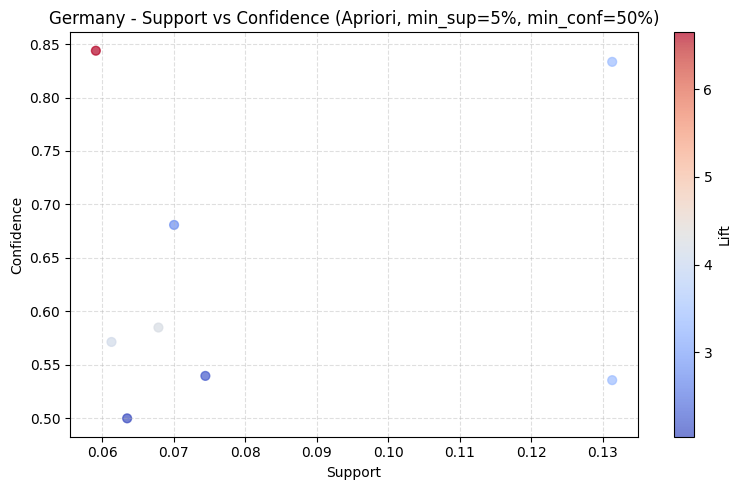

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# FP-GROWTH - Germany
print("=" * 60)
print("5a. FP-GROWTH - Germany | min_sup=5%, min_conf=50%")
print("=" * 60)

freq_de_fp = fpgrowth(basket_de_bool, min_support=0.05, use_colnames=True)
rules_de_fp = association_rules(freq_de_fp, metric="confidence", min_threshold=0.5)
rules_de_fp = rules_de_fp.sort_values(["confidence", "lift"], ascending=[False, False])
print(f"Số tập phổ biến (FP-Growth): {len(freq_de_fp)}")
print(f"Số luật kết hợp (FP-Growth): {len(rules_de_fp)}")
print("\nTop 15 luật:")
print(rules_de_fp[["antecedents", "consequents", "support", "confidence", "lift"]].head(15))

# Scatter plot Germany
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(rules_de["support"], rules_de["confidence"],
                c=rules_de["lift"], cmap="coolwarm", alpha=0.7, s=40)
plt.colorbar(sc, label="Lift")
ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.set_title("Germany - Support vs Confidence (Apriori, min_sup=5%, min_conf=50%)")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Câu 5b: Nước Pháp (France) - min_sup=7%, min_conf=70%

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# Lấy dữ liệu France
basket_fr = (df[df["Country"] == "France"]
             .groupby(["InvoiceNo", "Description"])["Quantity"]
             .sum().unstack().reset_index().fillna(0)
             .set_index("InvoiceNo"))

basket_fr_bool = basket_fr.applymap(lambda x: 1 if x >= 1 else 0).astype(bool)
if "POSTAGE" in basket_fr_bool.columns:
    basket_fr_bool.drop(columns=["POSTAGE"], inplace=True)

print(f"Dữ liệu France: {basket_fr_bool.shape[0]} hóa đơn, {basket_fr_bool.shape[1]} mặt hàng")

# APRIORI - France (min_sup=7%, min_conf=70%)
print("=" * 60)
print("5b. APRIORI - France | min_sup=7%, min_conf=70%")
print("=" * 60)

freq_fr = apriori(basket_fr_bool, min_support=0.07, use_colnames=True)
freq_fr = freq_fr.sort_values("support", ascending=False)
print(f"Số tập phổ biến: {len(freq_fr)}")
print("Top 15 tập phổ biến:")
print(freq_fr.head(15))

rules_fr = association_rules(freq_fr, metric="confidence", min_threshold=0.7)
rules_fr = rules_fr.sort_values(["confidence", "lift"], ascending=[False, False])
print(f"\nSố luật kết hợp: {len(rules_fr)}")
print("\nTop 15 luật kết hợp:")
print(rules_fr[["antecedents", "consequents", "support", "confidence", "lift"]].head(15))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Dữ liệu France: 392 hóa đơn, 1562 mặt hàng
5b. APRIORI - France | min_sup=7%, min_conf=70%
Số tập phổ biến: 51
Top 15 tập phổ biến:
     support                              itemsets
22  0.188776                  (RABBIT NIGHT LIGHT)
26  0.181122       (RED TOADSTOOL LED NIGHT LIGHT)
21  0.170918    (PLASTERS IN TIN WOODLAND ANIMALS)
18  0.168367       (PLASTERS IN TIN CIRCUS PARADE)
30  0.158163  (ROUND SNACK BOXES SET OF4 WOODLAND)
11  0.153061             (LUNCH BAG RED RETROSPOT)
14  0.142857    (LUNCH BOX WITH CUTLERY RETROSPOT)
19  0.137755            (PLASTERS IN TIN SPACEBOY)
33  0.137755         (SET/6 RED SPOTTY PAPER CUPS)
24  0.137755            (RED RETROSPOT MINI CASES)
32  0.132653  (SET/20 RED RETROSPOT PAPER NAPKINS)
34  0.127551       (SET/6 RED SPOTTY PAPER PLATES)
9   0.125000              (LUNCH BAG APPLE DESIGN)
27  0.125000            (REGENCY CAKESTAND 3 TIER)
36  0.125000                  (SPACEBOY LUNCH BOX)

Số luật kết hợp: 20

Top 15 luật kết hợp:
         

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
5b. FP-GROWTH - France | min_sup=7%, min_conf=70%
Số tập phổ biến (FP-Growth): 51
Số luật kết hợp (FP-Growth): 20

Top 15 luật:
                                          antecedents  \
12  (SET/6 RED SPOTTY PAPER CUPS, SET/20 RED RETRO...   
13  (SET/6 RED SPOTTY PAPER PLATES, SET/20 RED RET...   
8                     (SET/6 RED SPOTTY PAPER PLATES)   
7                       (SET/6 RED SPOTTY PAPER CUPS)   
3                          (ALARM CLOCK BAKELIKE RED)   
2                        (ALARM CLOCK BAKELIKE GREEN)   
11  (SET/6 RED SPOTTY PAPER CUPS, SET/6 RED SPOTTY...   
9                     (SET/6 RED SPOTTY PAPER PLATES)   
4                          (ALARM CLOCK BAKELIKE RED)   
15                    (SET/6 RED SPOTTY PAPER PLATES)   
10               (SET/20 RED RETROSPOT PAPER NAPKINS)   
19               (SET/20 RED RETROSPOT PAPER NAPKINS)   
0                        (ALARM CLOCK BAKELIKE GREEN)   
6                      

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

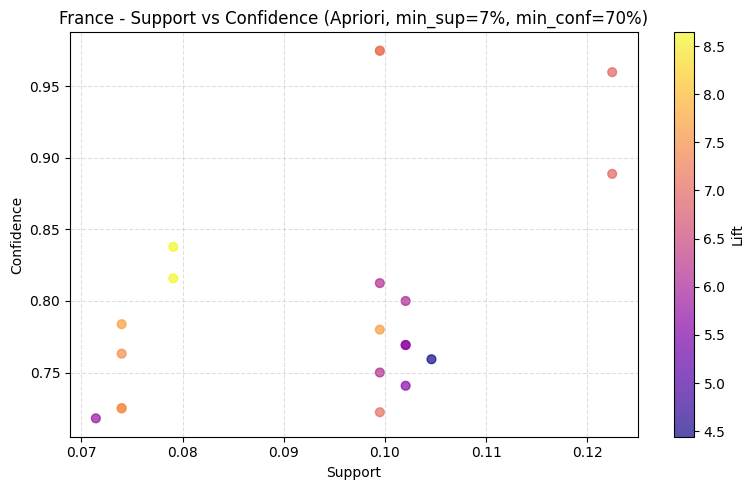

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# FP-GROWTH - France
print("=" * 60)
print("5b. FP-GROWTH - France | min_sup=7%, min_conf=70%")
print("=" * 60)

freq_fr_fp = fpgrowth(basket_fr_bool, min_support=0.07, use_colnames=True)
rules_fr_fp = association_rules(freq_fr_fp, metric="confidence", min_threshold=0.7)
rules_fr_fp = rules_fr_fp.sort_values(["confidence", "lift"], ascending=[False, False])
print(f"Số tập phổ biến (FP-Growth): {len(freq_fr_fp)}")
print(f"Số luật kết hợp (FP-Growth): {len(rules_fr_fp)}")
print("\nTop 15 luật:")
print(rules_fr_fp[["antecedents", "consequents", "support", "confidence", "lift"]].head(15))

# Scatter plot France
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(rules_fr["support"], rules_fr["confidence"],
                c=rules_fr["lift"], cmap="plasma", alpha=0.7, s=40)
plt.colorbar(sc, label="Lift")
ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.set_title("France - Support vs Confidence (Apriori, min_sup=7%, min_conf=70%)")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Câu 6: Groceries Dataset - So sánh thời gian Apriori vs FP-Growth

In [10]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

# Cai dat thu vien
!pip install mlxtend -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from mlxtend.frequent_patterns import apriori, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

# Doc Groceries dataset
transactions = []
with open("Groceries.csv", "r") as f:
    for line in f:
        line = line.strip()
        if line:
            items = [item.strip() for item in line.split(",")]
            items = [i for i in items if i]  # bo item rong
            transactions.append(items)

print("So giao dich:", len(transactions))
print("Vi du 5 giao dich dau:")
for t in transactions[:5]:
    print(" ", t)

# Chuyen ve one-hot encoding
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_groceries = pd.DataFrame(te_array, columns=te.columns_)
print("\nKich thuoc sau encoding:", df_groceries.shape)
print("So items:", len(te.columns_))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046


Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().

So giao dich: 9835
Vi du 5 giao dich dau:
  ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
  ['tropical fruit', 'yogurt', 'coffee']
  ['whole milk']
  ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads']
  ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']

Kich thuoc sau encoding: (9835, 169)
So items: 169


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [11]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

import time
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth

# Dung max_len=2 de gioi han do phuc tap
# min_sup tu 0.01% den 0.1% (dung 5 moc dai dien)
min_sups = [0.0001, 0.0003, 0.0005, 0.0007, 0.001]
labels   = ["0.01%", "0.03%", "0.05%", "0.07%", "0.1%"]

times_apriori  = []
times_fp       = []
counts_apriori = []
counts_fp      = []

print(f"{'min_sup':<8} {'Apriori(s)':<13} {'FP-Growth(s)':<15} {'#A':<8} {'#FP'}")
print("-" * 50)

for ms, lbl in zip(min_sups, labels):
    # a) Apriori - gioi han max_len=2 de tranh bao gio roi
    t0 = time.time()
    freq_a = apriori(df_groceries, min_support=ms,
                     use_colnames=True, max_len=2, low_memory=True)
    ta = round(time.time() - t0, 3)

    # b) FP-Growth - khong can gioi han, chay nhanh hon nhieu
    t0 = time.time()
    freq_f = fpgrowth(df_groceries, min_support=ms,
                      use_colnames=True, max_len=2)
    tf = round(time.time() - t0, 3)

    times_apriori.append(ta)
    times_fp.append(tf)
    counts_apriori.append(len(freq_a))
    counts_fp.append(len(freq_f))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
min_sup  Apriori(s)    FP-Growth(s)    #A       #FP
--------------------------------------------------


Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

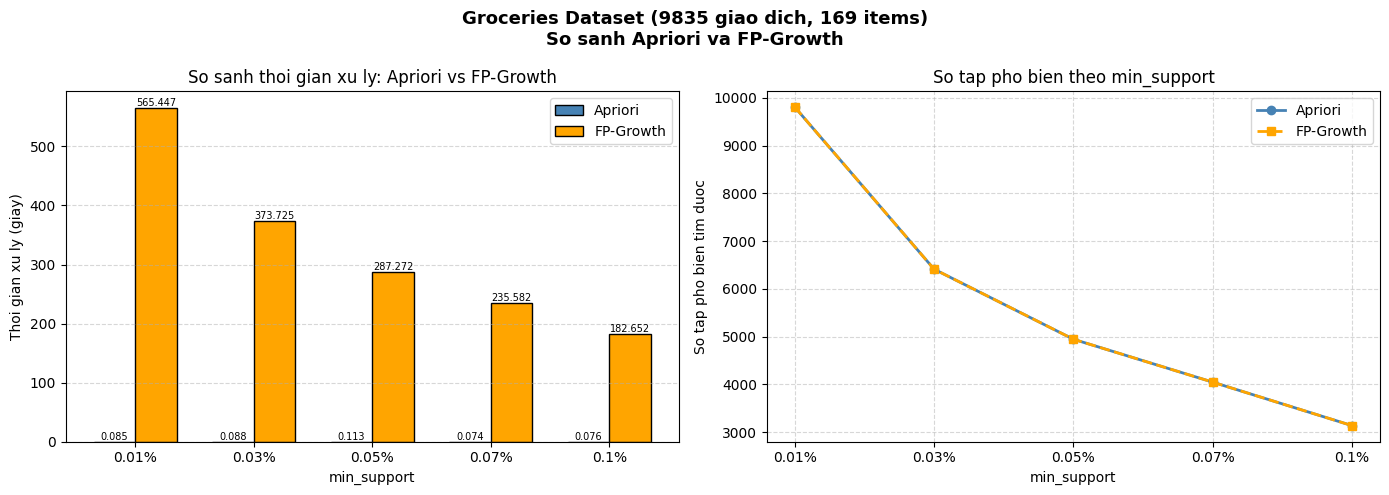

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


--- Bang ket qua ---
min_sup  Apriori (s)  FP-Growth (s)  So sets (Apriori)  So sets (FP-Growth)
  0.01%        0.085        565.447               9805                 9805
  0.03%        0.088        373.725               6412                 6412
  0.05%        0.113        287.272               4946                 4946
  0.07%        0.074        235.582               4048                 4048
   0.1%        0.076        182.652               3138                 3138

=== NHAN XET VA GIAI THICH ===
1. Ca hai thuat toan cho cung so luong tap pho bien (ket qua giong nhau).
2. FP-Growth nhanh hon Apriori vi:
   - Apriori: lap di lap lai qua tung buoc, sinh ung vien nhieu
   - FP-Growth: chi duyet co so lieu 2 lan, luu tru bang cay FP-Tree
3. Khi min_sup giam, so tap pho bien tang manh va thoi gian xu ly tang dang ke.
4. Voi dataset lon (9835 giao dich, 169 items), uu the cua FP-Growth cang ro rang.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [12]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = range(len(labels))
w = 0.35

# Bieu do 1: Thoi gian xu ly
bars1 = axes[0].bar([i - w/2 for i in x], times_apriori, w,
                    label="Apriori", color="steelblue", edgecolor="black")
bars2 = axes[0].bar([i + w/2 for i in x], times_fp, w,
                    label="FP-Growth", color="orange", edgecolor="black")
axes[0].set_xlabel("min_support")
axes[0].set_ylabel("Thoi gian xu ly (giay)")
axes[0].set_title("So sanh thoi gian xu ly: Apriori vs FP-Growth")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(labels)
axes[0].legend()
axes[0].grid(True, axis="y", linestyle="--", alpha=0.5)

# Nhan so len cot
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.001,
                 str(round(h, 3)), ha="center", va="bottom", fontsize=7)
for bar in bars2:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.001,
                 str(round(h, 3)), ha="center", va="bottom", fontsize=7)

# Bieu do 2: So tap pho bien
axes[1].plot(labels, counts_apriori, "o-",
             label="Apriori", color="steelblue", linewidth=2, markersize=6)
axes[1].plot(labels, counts_fp, "s--",
             label="FP-Growth", color="orange", linewidth=2, markersize=6)
axes[1].set_xlabel("min_support")
axes[1].set_ylabel("So tap pho bien tim duoc")
axes[1].set_title("So tap pho bien theo min_support")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Groceries Dataset (9835 giao dich, 169 items)\nSo sanh Apriori va FP-Growth",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# In bang ket qua
print("\n--- Bang ket qua ---")
result_df = pd.DataFrame({
    "min_sup": labels,
    "Apriori (s)": times_apriori,
    "FP-Growth (s)": times_fp,
    "So sets (Apriori)": counts_apriori,
    "So sets (FP-Growth)": counts_fp
})
print(result_df.to_string(index=False))

print("""
=== NHAN XET VA GIAI THICH ===
1. Ca hai thuat toan cho cung so luong tap pho bien (ket qua giong nhau).
2. FP-Growth nhanh hon Apriori vi:
   - Apriori: lap di lap lai qua tung buoc, sinh ung vien nhieu
   - FP-Growth: chi duyet co so lieu 2 lan, luu tru bang cay FP-Tree
3. Khi min_sup giam, so tap pho bien tang manh va thoi gian xu ly tang dang ke.
4. Voi dataset lon (9835 giao dich, 169 items), uu the cua FP-Growth cang ro rang.
""")